In [19]:
#installing libraries

!pip -q install pybullet

import os, json, math
import numpy as np
import pybullet as p
import matplotlib.pyplot as plt

WORKDIR = "/content/smart_warehouse_task1"
os.makedirs(WORKDIR, exist_ok=True)

print("Environment ready.")


Environment ready.


In [20]:
#building URDF models

def write_urdf(filename, xml):
    path = os.path.join(WORKDIR, filename)
    with open(path, "w") as f:
        f.write(xml)
    return path

# Cardboard shipping carton: realistic proportions for a warehouse package.
BOX_URDF = '''<?xml version="1.0"?>
<robot name="shipping_carton">
  <link name="base">
    <visual><origin xyz="0 0 0.24"/><geometry><box size="0.62 0.46 0.48"/></geometry>
      <material name="cardboard"><color rgba="0.58 0.34 0.13 1"/></material></visual>
    <collision><origin xyz="0 0 0.24"/><geometry><box size="0.62 0.46 0.48"/></geometry></collision>
  </link>
</robot>
'''


# Realistic selective pallet-racking bay:
# four uprights, multiple horizontal beams and two shelf/deck levels.
RACK_URDF = '''<?xml version="1.0"?>
<robot name="selective_pallet_rack">
  <link name="base"/>

  <link name="upright_fl"><visual><origin xyz="-1.72 -0.42 1.80"/><geometry><box size="0.12 0.12 3.60"/></geometry>
    <material name="racksteel"><color rgba="0.12 0.16 0.20 1"/></material></visual>
    <collision><origin xyz="-1.72 -0.42 1.80"/><geometry><box size="0.12 0.12 3.60"/></geometry></collision></link>
  <joint name="j_ufl" type="fixed"><parent link="base"/><child link="upright_fl"/><origin xyz="0 0 0"/></joint>

  <link name="upright_fr"><visual><origin xyz="1.72 -0.42 1.80"/><geometry><box size="0.12 0.12 3.60"/></geometry>
    <material name="racksteel"/></visual><collision><origin xyz="1.72 -0.42 1.80"/><geometry><box size="0.12 0.12 3.60"/></geometry></collision></link>
  <joint name="j_ufr" type="fixed"><parent link="base"/><child link="upright_fr"/><origin xyz="0 0 0"/></joint>

  <link name="upright_bl"><visual><origin xyz="-1.72 0.42 1.80"/><geometry><box size="0.12 0.12 3.60"/></geometry>
    <material name="racksteel"/></visual><collision><origin xyz="-1.72 0.42 1.80"/><geometry><box size="0.12 0.12 3.60"/></geometry></collision></link>
  <joint name="j_ubl" type="fixed"><parent link="base"/><child link="upright_bl"/><origin xyz="0 0 0"/></joint>

  <link name="upright_br"><visual><origin xyz="1.72 0.42 1.80"/><geometry><box size="0.12 0.12 3.60"/></geometry>
    <material name="racksteel"/></visual><collision><origin xyz="1.72 0.42 1.80"/><geometry><box size="0.12 0.12 3.60"/></geometry></collision></link>
  <joint name="j_ubr" type="fixed"><parent link="base"/><child link="upright_br"/><origin xyz="0 0 0"/></joint>

  <link name="beam_1"><visual><origin xyz="0 -0.42 0.72"/><geometry><box size="3.55 0.12 0.14"/></geometry><material name="beam"><color rgba="0.95 0.50 0.08 1"/></material></visual>
    <collision><origin xyz="0 -0.42 0.72"/><geometry><box size="3.55 0.12 0.14"/></geometry></collision></link>
  <joint name="j_b1" type="fixed"><parent link="base"/><child link="beam_1"/><origin xyz="0 0 0"/></joint>
  <link name="beam_2"><visual><origin xyz="0 0.42 0.72"/><geometry><box size="3.55 0.12 0.14"/></geometry><material name="beam"/></visual>
    <collision><origin xyz="0 0.42 0.72"/><geometry><box size="3.55 0.12 0.14"/></geometry></collision></link>
  <joint name="j_b2" type="fixed"><parent link="base"/><child link="beam_2"/><origin xyz="0 0 0"/></joint>

  <link name="beam_3"><visual><origin xyz="0 -0.42 1.82"/><geometry><box size="3.55 0.12 0.14"/></geometry><material name="beam"/></visual>
    <collision><origin xyz="0 -0.42 1.82"/><geometry><box size="3.55 0.12 0.14"/></geometry></collision></link>
  <joint name="j_b3" type="fixed"><parent link="base"/><child link="beam_3"/><origin xyz="0 0 0"/></joint>
  <link name="beam_4"><visual><origin xyz="0 0.42 1.82"/><geometry><box size="3.55 0.12 0.14"/></geometry><material name="beam"/></visual>
    <collision><origin xyz="0 0.42 1.82"/><geometry><box size="3.55 0.12 0.14"/></geometry></collision></link>
  <joint name="j_b4" type="fixed"><parent link="base"/><child link="beam_4"/><origin xyz="0 0 0"/></joint>

  <link name="beam_5"><visual><origin xyz="0 -0.42 2.92"/><geometry><box size="3.55 0.12 0.14"/></geometry><material name="beam"/></visual>
    <collision><origin xyz="0 -0.42 2.92"/><geometry><box size="3.55 0.12 0.14"/></geometry></collision></link>
  <joint name="j_b5" type="fixed"><parent link="base"/><child link="beam_5"/><origin xyz="0 0 0"/></joint>
  <link name="beam_6"><visual><origin xyz="0 0.42 2.92"/><geometry><box size="3.55 0.12 0.14"/></geometry><material name="beam"/></visual>
    <collision><origin xyz="0 0.42 2.92"/><geometry><box size="3.55 0.12 0.14"/></geometry></collision></link>
  <joint name="j_b6" type="fixed"><parent link="base"/><child link="beam_6"/><origin xyz="0 0 0"/></joint>

  <link name="deck_1"><visual><origin xyz="0 0 0.82"/><geometry><box size="3.35 0.78 0.06"/></geometry><material name="deck"><color rgba="0.30 0.33 0.35 1"/></material></visual>
    <collision><origin xyz="0 0 0.82"/><geometry><box size="3.35 0.78 0.06"/></geometry></collision></link>
  <joint name="j_d1" type="fixed"><parent link="base"/><child link="deck_1"/><origin xyz="0 0 0"/></joint>
  <link name="deck_2"><visual><origin xyz="0 0 1.92"/><geometry><box size="3.35 0.78 0.06"/></geometry><material name="deck"/></visual>
    <collision><origin xyz="0 0 1.92"/><geometry><box size="3.35 0.78 0.06"/></geometry></collision></link>
  <joint name="j_d2" type="fixed"><parent link="base"/><child link="deck_2"/><origin xyz="0 0 0"/></joint>
</robot>
'''


BARRIER_URDF = '''<?xml version="1.0"?>
<robot name="warehouse_safety_barrier">
  <link name="barrier">
    <visual><origin xyz="0 0 0.50"/><geometry><box size="2.80 0.10 1.00"/></geometry>
      <material name="guardrail"><color rgba="0.95 0.65 0.05 1"/></material></visual>
    <collision><origin xyz="0 0 0.50"/><geometry><box size="2.80 0.10 1.00"/></geometry></collision>
  </link>
</robot>
'''


LANDMARK_URDF = '''<?xml version="1.0"?>
<robot name="localisation_marker">
  <link name="landmark">
    <visual><origin xyz="0 0 0.75"/><geometry><cylinder radius="0.16" length="1.50"/></geometry>
      <material name="marker"><color rgba="0.05 0.25 0.70 1"/></material></visual>
    <collision><origin xyz="0 0 0.75"/><geometry><cylinder radius="0.16" length="1.50"/></geometry></collision>
  </link>
</robot>
'''


ROBOT_URDF = '''<?xml version="1.0"?>
<robot name="two_wheel_warehouse_amr">
  <link name="base">
    <visual><origin xyz="0 0 0.25"/><geometry><box size="1.05 0.68 0.38"/></geometry>
      <material name="robot"><color rgba="0.16 0.25 0.32 1"/></material></visual>
    <collision><origin xyz="0 0 0.25"/><geometry><box size="1.05 0.68 0.38"/></geometry></collision>
  </link>
  <link name="upper_deck"><visual><origin xyz="0 0 0.53"/><geometry><box size="0.72 0.56 0.16"/></geometry>
    <material name="deck"><color rgba="0.24 0.31 0.35 1"/></material></visual></link>
  <joint name="upper_deck_joint" type="fixed"><parent link="base"/><child link="upper_deck"/><origin xyz="0 0 0"/></joint>
  <link name="left_wheel"><visual><geometry><cylinder radius="0.22" length="0.15"/></geometry>
    <material name="wheel"><color rgba="0.035 0.035 0.035 1"/></material></visual>
    <collision><geometry><cylinder radius="0.22" length="0.15"/></geometry></collision></link>
  <link name="right_wheel"><visual><geometry><cylinder radius="0.22" length="0.15"/></geometry>
    <material name="wheel"><color rgba="0.035 0.035 0.035 1"/></material></visual>
    <collision><geometry><cylinder radius="0.22" length="0.15"/></geometry></collision></link>
  <link name="front_caster"><visual><geometry><sphere radius="0.10"/></geometry>
    <material name="caster"><color rgba="0.10 0.10 0.10 1"/></material></visual>
    <collision><geometry><sphere radius="0.10"/></geometry></collision></link>
  <joint name="left_wheel_joint" type="continuous"><parent link="base"/><child link="left_wheel"/>
    <origin xyz="0 0.40 0.22" rpy="1.5708 0 0"/><axis xyz="0 0 1"/></joint>
  <joint name="right_wheel_joint" type="continuous"><parent link="base"/><child link="right_wheel"/>
    <origin xyz="0 -0.40 0.22" rpy="1.5708 0 0"/><axis xyz="0 0 1"/></joint>
  <joint name="caster_joint" type="fixed"><parent link="base"/><child link="front_caster"/>
    <origin xyz="0.43 0 0.08"/></joint>
</robot>
'''


models = {
    "crate.urdf": BOX_URDF,
    "rack.urdf": RACK_URDF,
    "barrier.urdf": BARRIER_URDF,
    "landmark.urdf": LANDMARK_URDF,
    "two_wheel_robot.urdf": ROBOT_URDF,
}

for filename, xml in models.items():
    write_urdf(filename, xml)

print("URDF models created:", list(models))


URDF models created: ['crate.urdf', 'rack.urdf', 'barrier.urdf', 'landmark.urdf', 'two_wheel_robot.urdf']


In [21]:
#building semantic world

semantic_world = {
    "charging_station": {"role":"zone","category":"charging","function":"Robot docking and recharge","navigation_priority":"mission_start_end","position":(-7.0,-5.8)},
    "pickup_zone": {"role":"zone","category":"pickup","function":"Collect inventory package","navigation_priority":"mission_goal","position":(6.2,-4.4)},
    "delivery_zone": {"role":"zone","category":"delivery","function":"Drop off inventory package","navigation_priority":"mission_goal","position":(6.2,0.0)},
    "inspection_zone": {"role":"zone","category":"inspection","function":"Inspect package or warehouse state","navigation_priority":"mission_goal","position":(2.0,5.2)},
    "restricted_zone": {"role":"restricted_area","category":"safety","function":"Area prohibited to mobile robot","navigation_priority":"avoid","position":(7.0,5.8)},
    "rack_A": {"role":"obstacle","category":"storage_rack","function":"Stores inventory crates","navigation_priority":"avoid","position":(-5.0,2.4)},
    "rack_B": {"role":"obstacle","category":"storage_rack","function":"Stores inventory crates","navigation_priority":"avoid","position":(0.0,2.4)},
    "rack_C": {"role":"obstacle","category":"storage_rack","function":"Stores inventory crates","navigation_priority":"avoid","position":(-5.0,-0.8)},
    "rack_D": {"role":"obstacle","category":"storage_rack","function":"Stores inventory crates","navigation_priority":"avoid","position":(0.0,-0.8)},
    "barrier_A": {"role":"obstacle","category":"safety_barrier","function":"Separates traffic from restricted operations","navigation_priority":"avoid","position":(5.0,4.0)},
    "barrier_B": {"role":"obstacle","category":"safety_barrier","function":"Separates delivery area from traffic","navigation_priority":"avoid","position":(4.5,-2.0)},
    "landmark_1": {"role":"landmark","category":"localisation","function":"Fixed reference for robot localisation","navigation_priority":"reference","position":(-8.5,-6.5)},
    "landmark_2": {"role":"landmark","category":"localisation","function":"Fixed reference for robot localisation","navigation_priority":"reference","position":(8.5,-6.5)},
    "landmark_3": {"role":"landmark","category":"localisation","function":"Fixed reference for robot localisation","navigation_priority":"reference","position":(-8.5,6.5)},
    "landmark_4": {"role":"landmark","category":"localisation","function":"Fixed reference for robot localisation","navigation_priority":"reference","position":(8.5,2.0)},
}

mission = ["charging_station","pickup_zone","delivery_zone","inspection_zone","charging_station"]

print("Mission:", " → ".join(mission))


Mission: charging_station → pickup_zone → delivery_zone → inspection_zone → charging_station


In [22]:
# building warehouse environment

if p.isConnected():
    p.disconnect()
p.connect(p.DIRECT)
p.resetSimulation()
p.setGravity(0,0,-9.81)
p.setAdditionalSearchPath(WORKDIR)

def visual_box(position, half_extents, rgba, collision=False):
    visual = p.createVisualShape(p.GEOM_BOX, halfExtents=half_extents, rgbaColor=rgba)
    col = p.createCollisionShape(p.GEOM_BOX, halfExtents=half_extents) if collision else -1
    return p.createMultiBody(baseMass=0, baseCollisionShapeIndex=col,
                             baseVisualShapeIndex=visual, basePosition=position)

# ------------------------------------------------------------------
# REALISTIC WAREHOUSE BASE
# ------------------------------------------------------------------
# Concrete/epoxy industrial floor.
visual_box((0,0,-0.08),(10,8,0.08),(0.58,0.60,0.61,1),True)

# Perimeter walls, kept low enough for overhead camera views.
visual_box((0,7.85,2.0),(10,0.15,2.0),(0.78,0.79,0.78,1),True)
visual_box((0,-7.85,2.0),(10,0.15,2.0),(0.78,0.79,0.78,1),True)
visual_box((-9.85,0,2.0),(0.15,7.85,2.0),(0.78,0.79,0.78,1),True)
visual_box((9.85,0,2.0),(0.15,7.85,2.0),(0.78,0.79,0.78,1),True)

# Main warehouse aisle markings: white pedestrian/traffic lines.
for x in [-8.0,-3.0,2.0,7.0]:
    visual_box((x,0,0.006),(0.025,7.35,0.006),(0.95,0.95,0.93,1))

# Yellow safety boundary markings near storage/traffic areas.
for y in [-5.2,-2.0,1.3,4.8]:
    visual_box((0,y,0.008),(9.35,0.025,0.008),(0.95,0.72,0.05,1))

# Zebra-style pedestrian crossing near the delivery side.
for x in np.arange(4.0,5.8,0.35):
    visual_box((x,-2.0,0.010),(0.10,0.75,0.008),(0.95,0.95,0.95,1))

body_ids = {}

# ------------------------------------------------------------------
# PALLET RACKING
# ------------------------------------------------------------------
rack_positions = {
    "rack_A":(-5.0,2.4), "rack_B":(0.0,2.4),
    "rack_C":(-5.0,-0.8), "rack_D":(0.0,-0.8)
}

for name,(x,y) in rack_positions.items():
    body_ids[name] = p.loadURDF(os.path.join(WORKDIR,"rack.urdf"),[x,y,0],useFixedBase=True)

# Rack end-protection / upright guards.
for x,y in rack_positions.values():
    for side in [-1,1]:
        visual_box((x + side*1.90, y-0.52, 0.32),(0.12,0.12,0.32),(0.95,0.62,0.05,1),True)

# 20 realistic inventory cartons placed on rack decks.
crate_positions = []
crate_slots = [
    (-1.15,-0.10,0.84), (0.0,-0.10,0.84), (1.15,-0.10,0.84),
    (-0.58,0.10,1.94), (0.58,0.10,1.94)
]

for x0,y0 in rack_positions.values():
    for dx,dy,z in crate_slots:
        crate_positions.append((x0+dx,y0+dy,z))

for i,(x,y,z) in enumerate(crate_positions,1):
    name = f"inventory_crate_{i:02d}"
    body_ids[name] = p.loadURDF(os.path.join(WORKDIR,"crate.urdf"),[x,y,z],useFixedBase=True)
    semantic_world[name] = {
        "role":"inventory","category":"shipping_carton",
        "function":"Stored warehouse inventory on pallet rack",
        "navigation_priority":"avoid","position":(x,y)
    }

# ------------------------------------------------------------------
# SAFETY INFRASTRUCTURE
# ------------------------------------------------------------------
body_ids["barrier_A"] = p.loadURDF(os.path.join(WORKDIR,"barrier.urdf"),
                                   [5.0,4.0,0],useFixedBase=True)
body_ids["barrier_B"] = p.loadURDF(os.path.join(WORKDIR,"barrier.urdf"),
                                   [4.5,-2.0,0],useFixedBase=True,
                                   baseOrientation=p.getQuaternionFromEuler([0,0,math.pi/2]))

# Yellow/black-style safety bollards at selected traffic boundaries.
for bx,by in [(3.2,-4.4),(3.2,0.0),(3.2,4.0),(7.9,4.8)]:
    visual_box((bx,by,0.45),(0.10,0.10,0.45),(0.95,0.62,0.05,1),True)

# ------------------------------------------------------------------
# LOCALISATION LANDMARKS
# ------------------------------------------------------------------
for name in ["landmark_1","landmark_2","landmark_3","landmark_4"]:
    x,y = semantic_world[name]["position"]
    body_ids[name] = p.loadURDF(os.path.join(WORKDIR,"landmark.urdf"),
                                [x,y,0],useFixedBase=True)

# ------------------------------------------------------------------
# OPERATIONAL ZONES
# ------------------------------------------------------------------
zone_specs = {
    "charging_station": ((-7.0,-5.8),(1.35,1.0),(0.20,0.70,0.25,0.65)),
    "pickup_zone": ((6.2,-4.4),(1.35,1.0),(0.15,0.55,0.85,0.65)),
    "delivery_zone": ((6.2,0.0),(1.35,1.0),(0.85,0.65,0.15,0.65)),
    "inspection_zone": ((2.0,5.2),(1.5,1.0),(0.60,0.25,0.75,0.65)),
    "restricted_zone": ((7.0,5.8),(1.45,1.05),(0.85,0.18,0.18,0.55)),
}

for name,(pos,size,rgba) in zone_specs.items():
    x,y = pos
    hx,hy = size
    body_ids[name] = visual_box((x,y,0.012),(hx,hy,0.012),rgba)

# Docking bay markings around the charging station.
for x in [-8.0,-7.0,-6.0]:
    visual_box((x,-5.8,0.020),(0.035,0.95,0.010),(0.95,0.95,0.93,1))

# Restricted-zone posts.
for dx in [-1.35,1.35]:
    for dy in [-0.95,0.95]:
        visual_box((7.0+dx,5.8+dy,0.55),(0.07,0.07,0.55),(0.90,0.15,0.12,1),True)

# ------------------------------------------------------------------
# MOBILE ROBOT
# ------------------------------------------------------------------
robot_start = (-7.0,-4.0,0.05)
robot_id = p.loadURDF(os.path.join(WORKDIR,"two_wheel_robot.urdf"),
                      robot_start,useFixedBase=True)
body_ids["robot"] = robot_id
semantic_world["robot"] = {
    "role":"agent","category":"mobile_robot",
    "function":"Warehouse delivery, inspection and navigation",
    "navigation_priority":"active_agent","position":robot_start[:2]
}

print("Warehouse created.")
print("Pallet racks:", len(rack_positions))
print("Inventory cartons:", len(crate_positions))
print("Semantic entities:", len(semantic_world))


Warehouse created.
Pallet racks: 4
Inventory cartons: 20
Semantic entities: 36


In [23]:
#assigning queries and interaction by entity and roles

def query_by_role(role):
    return {k:v for k,v in semantic_world.items() if v.get("role")==role}

def query_by_category(category):
    return {k:v for k,v in semantic_world.items() if v.get("category")==category}

def nearest_entity(position, candidates=None):
    candidates = list(candidates) if candidates is not None else list(semantic_world)
    best, best_distance = None, float("inf")
    for name in candidates:
        if name not in semantic_world or "position" not in semantic_world[name]:
            continue
        d = math.dist(position, semantic_world[name]["position"][:2])
        if d < best_distance:
            best, best_distance = name, d
    return best, best_distance

def is_restricted(position):
    x,y = position
    rx,ry = semantic_world["restricted_zone"]["position"]
    return abs(x-rx) <= 1.45 and abs(y-ry) <= 1.05

print("Zone query:", list(query_by_role("zone")))
print("Obstacle query:", list(query_by_role("obstacle")))
print("Landmark query:", list(query_by_role("landmark")))
print("Crate count:", len(query_by_category("crate")))
print("Nearest landmark to origin:", nearest_entity((0,0), query_by_role("landmark")))
print("Safety query at (7.0,5.8):", "RESTRICTED" if is_restricted((7.0,5.8)) else "SAFE")


Zone query: ['charging_station', 'pickup_zone', 'delivery_zone', 'inspection_zone']
Obstacle query: ['rack_A', 'rack_B', 'rack_C', 'rack_D', 'barrier_A', 'barrier_B']
Landmark query: ['landmark_1', 'landmark_2', 'landmark_3', 'landmark_4']
Crate count: 0
Nearest landmark to origin: ('landmark_4', 8.73212459828649)
Safety query at (7.0,5.8): RESTRICTED


In [24]:
# Corridor-aware route: use the open perimeter and lower/upper transit corridors,
# avoiding direct diagonals through the storage-rack blocks.
mission_waypoints = [
    (-7.0, -5.8),   # charging
    (-7.0, -3.2),
    (3.0, -3.2),
    (6.2, -4.4),    # pickup
    (8.5, -4.4),
    (8.5,  0.0),
    (6.2,  0.0),    # delivery
    (8.5,  0.0),
    (8.5,  3.8),
    (4.0,  3.8),
    (2.0,  5.2),    # inspection
    (4.0,  3.8),
    (8.5,  3.8),
    (8.5, -5.8),
    (-7.0, -5.8),   # return to charging
]

def route_length(points):
    return sum(
        ((points[i][0]-points[i-1][0])**2 + (points[i][1]-points[i-1][1])**2)**0.5
        for i in range(1, len(points))
    )

print("Corridor-aware mission waypoints:")
for i, wp in enumerate(mission_waypoints, 1):
    print(f"  {i:02d}: {wp}")
print(f"Approximate route length: {route_length(mission_waypoints):.2f} m")


Corridor-aware mission waypoints:
  01: (-7.0, -5.8)
  02: (-7.0, -3.2)
  03: (3.0, -3.2)
  04: (6.2, -4.4)
  05: (8.5, -4.4)
  06: (8.5, 0.0)
  07: (6.2, 0.0)
  08: (8.5, 0.0)
  09: (8.5, 3.8)
  10: (4.0, 3.8)
  11: (2.0, 5.2)
  12: (4.0, 3.8)
  13: (8.5, 3.8)
  14: (8.5, -5.8)
  15: (-7.0, -5.8)
Approximate route length: 70.10 m


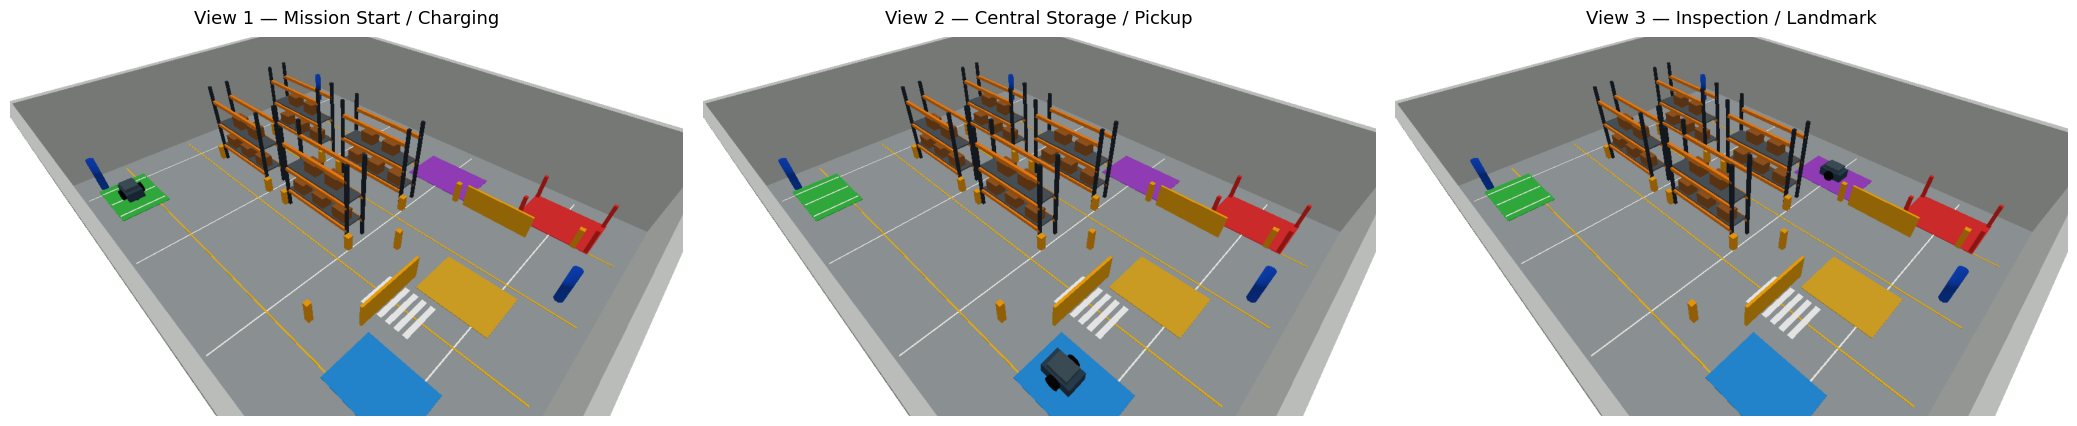

In [25]:
#three different camera viewpoints

camera_views = [
    # Wider, elevated view: keep the robot and charging area clearly visible
    # while showing the surrounding warehouse context.
    ("View 1 — Mission Start / Charging",
     (-7.0,-5.8,0.05), (1.0,-0.5,0.0), 13.0),

    # Central warehouse view: show the robot, storage racks and pickup area
    # together instead of tightly cropping around the robot.
    ("View 2 — Central Storage / Pickup",
     (5.8,-4.4,0.05), (1.0,-0.5,0.0), 13.0),

    # Upper warehouse view: show inspection, racks, landmarks and the
    # surrounding restricted-area context in one frame.
    ("View 3 — Inspection / Landmark",
     (2.0,5.2,0.05), (1.0,-0.5,0.0), 13.0),

]

def render_view(title, robot_position, target, distance, filename):
    p.resetBasePositionAndOrientation(
        robot_id, robot_position, p.getQuaternionFromEuler([0,0,0])
    )

    # Elevated diagonal camera with a wider field of view.  This keeps
    # the robot close to the visual centre while retaining enough warehouse
    # context for the objects, racks and semantic zones to be identifiable.
    eye = [
        target[0] + distance*0.58,
        target[1] - distance*0.58,
        target[2] + distance*0.78
    ]

    view = p.computeViewMatrix(
        cameraEyePosition=eye,
        cameraTargetPosition=target,
        cameraUpVector=[0,0,1]
    )

    proj = p.computeProjectionMatrixFOV(
        fov=55, aspect=16/9, nearVal=0.1, farVal=50
    )

    w,h = 1100,620
    img = p.getCameraImage(
        w,h,
        viewMatrix=view,
        projectionMatrix=proj,
        renderer=p.ER_TINY_RENDERER
    )

    rgb = np.reshape(img[2],(h,w,4))[:,:,:3]

    from PIL import Image
    Image.fromarray(rgb).save(filename)
    return rgb

rendered = []
for i,(title,pos,target,distance) in enumerate(camera_views,1):
    rendered.append((
        title,
        render_view(
            title, pos, target, distance,
            os.path.join(WORKDIR,f"view_{i}.png")
        )
    ))

fig = plt.figure(figsize=(21,7))
for i,(title,img) in enumerate(rendered,1):
    ax = fig.add_subplot(1,3,i)
    ax.imshow(img)
    ax.set_title(title, fontsize=13, pad=10)
    ax.axis("off")

plt.subplots_adjust(left=0.01,right=0.99,top=0.90,bottom=0.02,wspace=0.03)
plt.savefig(
    os.path.join(WORKDIR,"three_camera_views.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()


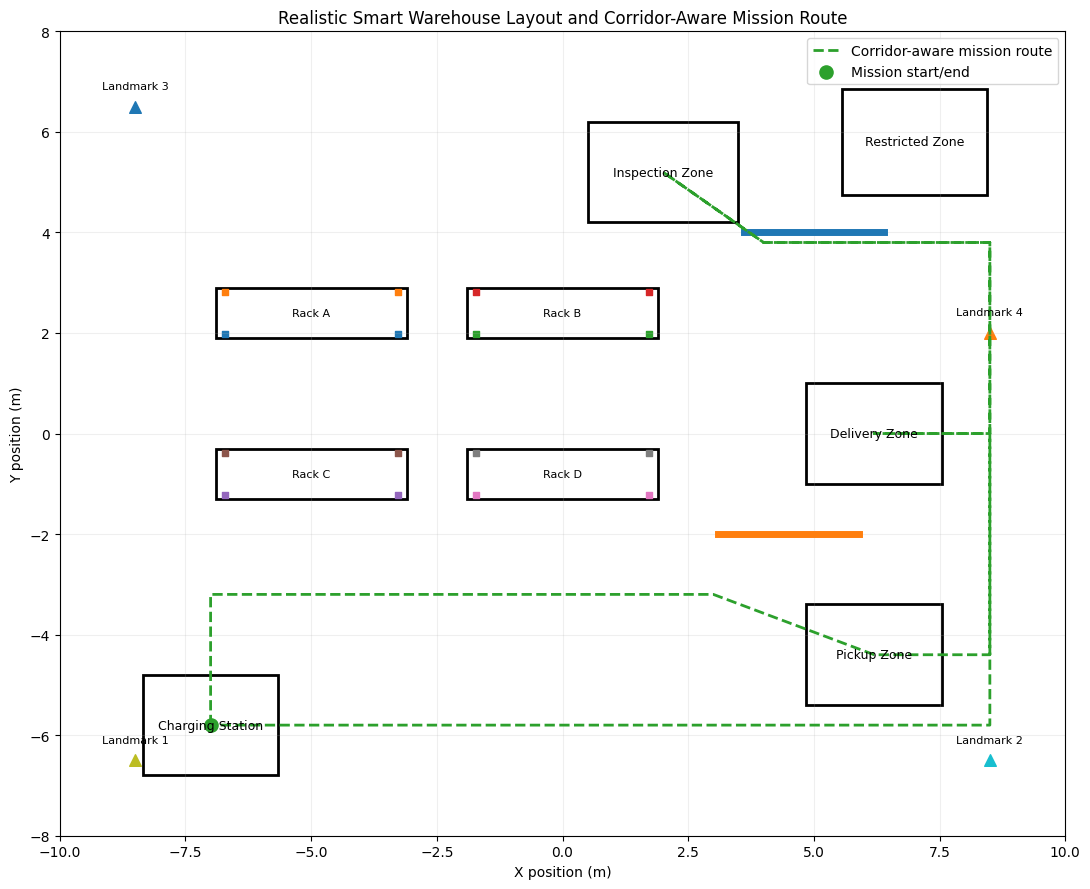

In [26]:
#structuring semantic map

fig, ax = plt.subplots(figsize=(12,9))
ax.set_xlim(-10,10)
ax.set_ylim(-8,8)
ax.set_aspect("equal")

# Zones
for name,(pos,size,rgba) in zone_specs.items():
    x,y = pos
    hx,hy = size
    ax.add_patch(plt.Rectangle((x-hx,y-hy),2*hx,2*hy,fill=False,linewidth=2))
    ax.text(x,y,name.replace("_"," ").title(),ha="center",va="center",fontsize=9)

# Realistic pallet-rack footprints and aisle labels
for name,(x,y) in rack_positions.items():
    ax.add_patch(plt.Rectangle((x-1.9,y-0.50),3.8,1.0,fill=False,linewidth=2))
    # Uprights
    ax.scatter([x-1.72,x+1.72],[y-0.42,y-0.42],s=18,marker="s")
    ax.scatter([x-1.72,x+1.72],[y+0.42,y+0.42],s=18,marker="s")
    ax.text(x,y,name.replace("_"," ").title(),ha="center",va="center",fontsize=8)

# Localisation landmarks
for name in ["landmark_1","landmark_2","landmark_3","landmark_4"]:
    x,y = semantic_world[name]["position"]
    ax.scatter([x],[y],s=70,marker="^")
    ax.text(x,y+0.35,name.replace("_"," ").title(),ha="center",fontsize=8)

# Safety barriers
for name in ["barrier_A","barrier_B"]:
    x,y = semantic_world[name]["position"]
    ax.plot([x-1.4,x+1.4],[y,y],linewidth=5)

# Corridor-aware route
ax.plot(
    [x for x,y in mission_waypoints],
    [y for x,y in mission_waypoints],
    linestyle="--",linewidth=2,label="Corridor-aware mission route"
)

# Mission start/end
cx,cy = semantic_world["charging_station"]["position"]
ax.scatter([cx],[cy],s=90,marker="o",label="Mission start/end")

ax.set_title("Realistic Smart Warehouse Layout and Corridor-Aware Mission Route")
ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.legend()
ax.grid(True,alpha=0.20)
plt.tight_layout()
plt.savefig(os.path.join(WORKDIR,"semantic_warehouse_map.png"),dpi=180,bbox_inches="tight")
plt.show()


In [27]:
#exporting semantic representation

semantic_export = {
    "scenario":"Smart Warehouse Delivery, Inspection and Safety Monitoring",
    "mission":mission,
    "entities":semantic_world
}

json_path = os.path.join(WORKDIR,"semantic_warehouse.json")
with open(json_path,"w") as f:
    json.dump(semantic_export,f,indent=2)

print("Exported semantic map:", json_path)


Exported semantic map: /content/smart_warehouse_task1/semantic_warehouse.json
